Factor Models

# Setup

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Import the libraries used in this lecture: `pandas` as `pd`, `yfinance` as `yf`, `pandas_datareader` as `pdr`, `matplotlib.pyplot` as `plt`, `seaborn` as `sns`, and `statsmodels.api` as `sm`. Uncomment and run the following code.

In [1]:
import pandas as pd
import yfinance as yf
import pandas_datareader as pdr # for FRED, Fama-French

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm # for OLS

# Factor Models

* Factor models are used in many financial applications, such as identifying the determinants of a security’s return as well as in cost of capital calculations, and performance evalution.
* Factors help explain the variation in a security’s return. 
* Here we will study two types of factor models
  - CAPM, a one-factor model
  - Fama-French 3-factor model

# CAPM

<mark>Q: What is the CAPM, and what does it say about a security's expected return?</mark>

* The formula for CAPM is:
$$E(r) = r_f + \beta \times E(r_M - r_f)$$
  - $r$ is the return on the stock
  - $r_f$ is the risk-free rate
  - $r_M$ is return on the market portfolio 
* To estimate the model using regression, we will add the residual term $\epsilon$ and intercept $\alpha$ and rearrange terms:

$$r - r_f = \alpha + \beta \times (r_{M} - r_f) + \epsilon$$


* So that we can regress stock EXCESS return $R \equiv r - r_f$ on market EXCESS return $R_M \equiv r_M -r_f$.

## Getting Data

* We will use IBM as example to apply CAPM. 
* The following code downloads the stock prices:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set `stock_symbol` to `"IBM"` and `star_date` to `"2007-1-1"`, then download the data into `df` with `yf.download()` using `auto_adjust=True`, `multi_level_index=False` and `progress=False`. Uncomment and run the following code.

In [2]:
stock_symbol = "IBM"
star_date = "2007-1-1"
df = yf.download(stock_symbol,
                  start=star_date,
                  auto_adjust=True,
                  multi_level_index=False,
                  progress=False)


Crumb fetch rate-limited (HTTP 429), continuing without crumb


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the last few rows of `df` with `.tail()`.

In [3]:
df.tail()

,Close,High,Low,Open,Volume
Date,,,,,
2026-10-23,253.559998,254.710007,247.029999,249.729996,5888000
2026-10-26,253.440002,256.000000,250.800003,253.009995,3745500
2026-10-27,250.250000,253.179993,249.130005,251.929993,3654800
2026-10-28,253.220001,253.850006,247.669998,248.490005,3698600
2026-10-29,258.279999,258.329987,247.800003,249.270004,3922200


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the `"Close"` column of `df` into a variable called `close`, and display its first few rows with `.head()`.

In [4]:
close = df['Close']
close.head()

Date
2007-01-03    49.842403
2007-01-04    50.375301
2007-01-05    49.919247
2007-01-08    50.677605
2007-01-09    51.277157
Name: Close, dtype: float64

## Monthly Return

* Next we calculate the *monthly* return on the stock

<mark>Q: How to calculate monthly returns from daily closing prices?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Downsample `close` to month-end frequency with `resample('ME').last()` and store it in `monthly_close`.

In [5]:
monthly_close = close.resample('ME').last()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `monthly_close`.

In [6]:
monthly_close.head()

Date
2007-01-31    50.805729
2007-02-28    47.767162
2007-03-31    48.445591
2007-04-30    52.531528
2007-05-31    55.001064
Freq: ME, Name: Close, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the monthly return with `pct_change()`, store it in `r_monthly`, and display the first few rows.

In [7]:
r_monthly = monthly_close.pct_change() * 100
r_monthly.head()

Date
2007-01-31         NaN
2007-02-28   -5.980756
2007-03-31    1.420283
2007-04-30    8.434075
2007-05-31    4.701055
Freq: ME, Name: Close, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Name the series by setting `r_monthly.name` to `'r_i'`, and display the first few rows.

In [8]:
r_monthly.name = 'r_i'
r_monthly.head()

Date
2007-01-31         NaN
2007-02-28   -5.980756
2007-03-31    1.420283
2007-04-30    8.434075
2007-05-31    4.701055
Freq: ME, Name: r_i, dtype: float64

<mark>Q: How to make two monthly series that come from different sources line up on the same index?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert `r_monthly`'s `DatetimeIndex` to a monthly `PeriodIndex` with `.index.to_period('M')`, so it will line up with the Fama-French data later.

In [9]:
r_monthly.index = r_monthly.index.to_period('M')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_monthly` again to confirm the new index.

In [10]:
r_monthly.head()

Date
2007-01         NaN
2007-02   -5.980756
2007-03    1.420283
2007-04    8.434075
2007-05    4.701055
Freq: M, Name: r_i, dtype: float64

## Make it a function

<mark>Q: How to turn the algorithm into a function?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Since the monthly return calculation will be repeatedly performed, let's collect the code and make it into a function. Uncomment and run the code below to have the function defined.

In [11]:
def getMonthlyReturn(df, name):
    close = df["Close"]
    monthly_close = close.resample('ME').last()
    r_monthly = monthly_close.pct_change() * 100
    r_monthly.name = name
    r_monthly.index = r_monthly.index.to_period('M')
    r_monthly.dropna(inplace=True)

    return r_monthly

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Call `getMonthlyReturn()` on `df` with the name `"r_i"`, and store the result in `r_i`.

In [12]:
r_i = getMonthlyReturn(df, 'r_i')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_i`.

In [13]:
r_i.head()

Date
2007-02   -5.980756
2007-03    1.420283
2007-04    8.434075
2007-05    4.701055
2007-06   -1.266420
Freq: M, Name: r_i, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_i` with the title `f"{stock_symbol} Monthly Return"`.

<Axes: title={'center': 'IBM Monthly Return'}, xlabel='Date'>

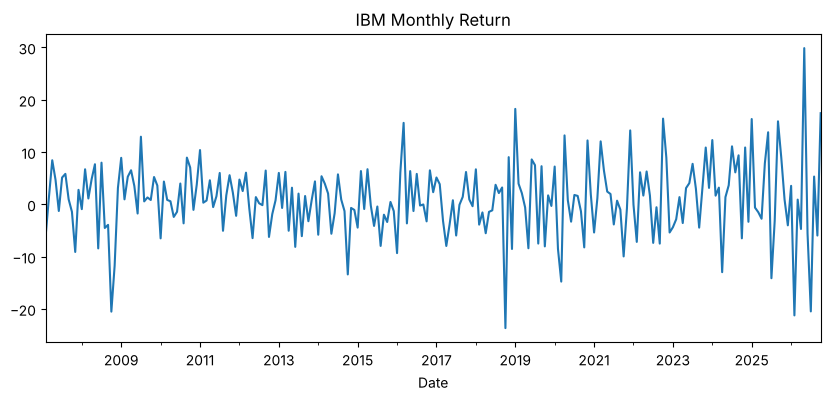

In [14]:
r_i.plot(title=f'{stock_symbol} Monthly Return', figsize=(10, 4))

## Market Return

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Fetch the monthly Fama-French 3-factor dataset into `ff_dict_monthly`. Uncomment and run the following code, and inspect `ff_dict_monthly`.

In [15]:
# Fetch the monthly Fama-French 3 Factors dataset
ff_dict_monthly = pdr.DataReader('F-F_Research_Data_Factors', 'famafrench', start="1900-01-01")

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ The monthly data is the DataFrame at index `[0]` of the dictionary — extract it into `ff_monthly`.

In [16]:
ff_monthly = ff_dict_monthly[0]

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the first few rows of `ff_monthly`.

In [17]:
ff_monthly.head()

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07,2.89,-2.42,-2.75,0.22
1926-08,2.64,-1.44,4.13,0.25
1926-09,0.38,-1.36,0.05,0.23
1926-10,-3.27,-0.18,0.78,0.32
1926-11,2.54,-0.17,-0.48,0.31


<mark>Q: How to recover the total market return from the Fama-French factors?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the total market return `r_m` by adding the risk-free rate `'RF'` back to the market premium `'Mkt-RF'`.

In [18]:
r_m = ff_monthly['Mkt-RF'] + ff_monthly['RF']
r_m.name = 'r_m'

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_m`.

In [19]:
r_m.head()

Date
1926-07    3.11
1926-08    2.89
1926-09    0.61
1926-10   -2.95
1926-11    2.85
Freq: M, Name: r_m, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_m` with the title `"S&P 500 Monthly Return"`.

<Axes: title={'center': 'S&P 500 Monthly Return'}, xlabel='Date'>

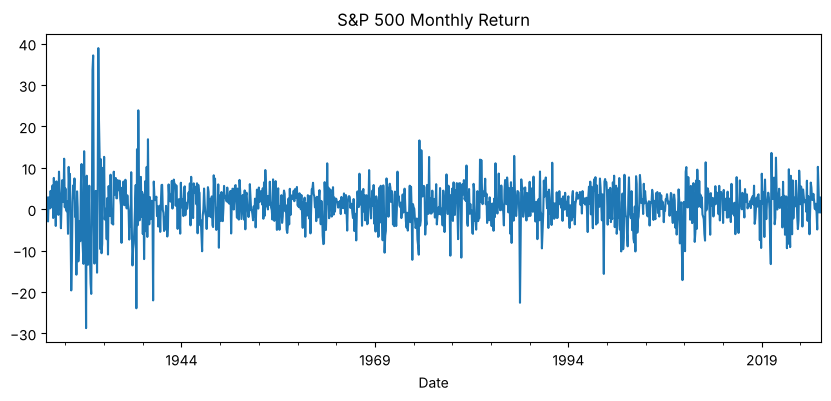

In [20]:
r_m.plot(title='S&P 500 Monthly Return', figsize=(10, 4))

## Risk-free Rate

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the risk-free rate column `'RF'` from `ff_monthly` into `r_f`.

In [21]:
r_f = ff_monthly['RF']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_f`.

In [22]:
r_f.head()

Date
1926-07    0.22
1926-08    0.25
1926-09    0.23
1926-10    0.32
1926-11    0.31
Freq: M, Name: RF, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_f` with the title `"Risk-free Rate"`.

<Axes: title={'center': 'Risk-free Rate'}, xlabel='Date'>

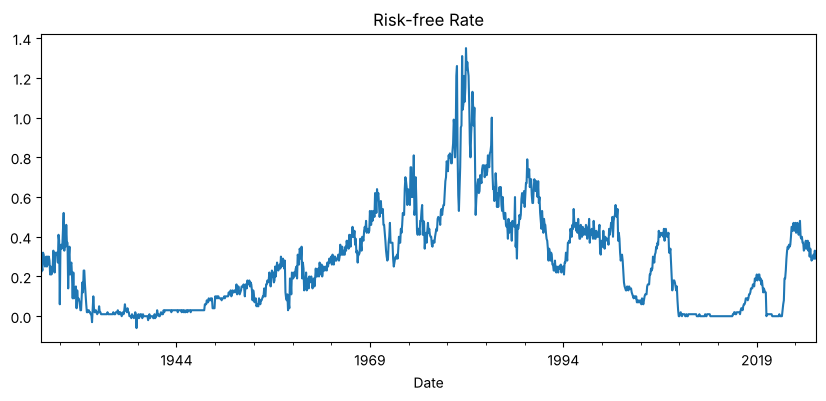

In [23]:
r_f.plot(title='Risk-free Rate', figsize=(10, 4))

## Combining the rates

<mark>Q: How to combine several return series into a single DataFrame?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Combine `r_i`, `r_m` and `r_f` into one DataFrame called `returns` with `pd.concat(..., axis=1)`, and drop the rows with missing values using `.dropna()`.

In [24]:
returns = pd.concat([r_i, r_m, r_f], axis=1).dropna()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the last few rows of `returns` with `.tail()`.

In [25]:
returns.tail()

,r_i,r_m,RF
Date,,,
2026-05,29.877823,5.22,0.31
2026-06,-5.570851,-0.78,0.29
2026-07,-20.468687,-0.28,0.33
2026-08,5.319771,2.85,0.29
2026-09,-5.960578,-0.76,0.31


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Rename the columns of `returns` to `["r_i", "r_m", "r_f"]`.

In [26]:
returns.columns = ['r_i', 'r_m', 'r_f']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `returns`.

<Axes: xlabel='Date'>

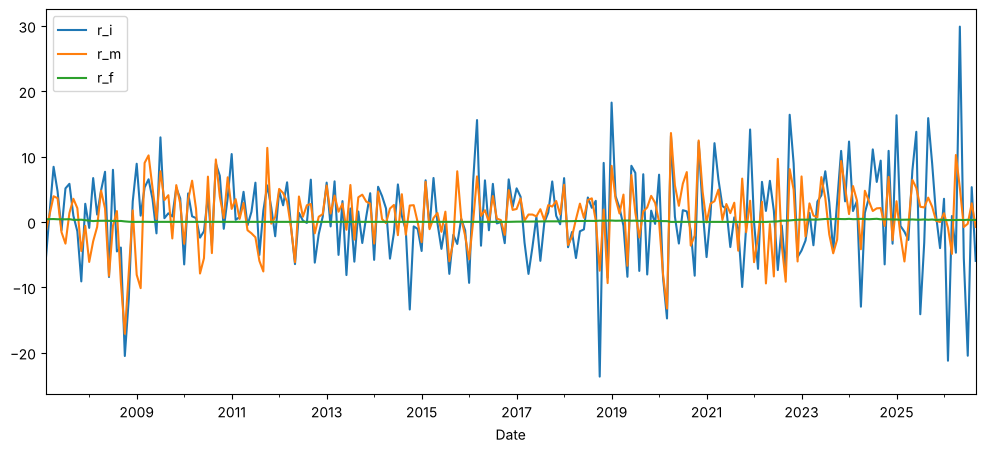

In [27]:
returns.plot(figsize=(12, 5))

## Calculate Excess Returns

<mark>Q: What is an excess return, and how to calculate it?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the excess return on the stock as `r_i` minus `r_f`, and store it in a new column `'R_i'`.

In [28]:
returns['R_i'] = returns['r_i'] - returns['r_f']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the excess return on the market as `r_m` minus `r_f`, and store it in a new column `'R_m'`.

In [29]:
returns['R_m'] = returns['r_m'] - returns['r_f']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `returns`.

In [30]:
returns.head()

,r_i,r_m,r_f,R_i,R_m
Date,,,,,
2007-02,-5.980756,-1.58,0.38,-6.360756,-1.96
2007-03,1.420283,1.14,0.43,0.990283,0.71
2007-04,8.434075,3.93,0.44,7.994075,3.49
2007-05,4.701055,3.64,0.41,4.291055,3.23
2007-06,-1.266420,-1.56,0.40,-1.666420,-1.96


## Scatter Plot: R_i vs. R_m

<mark>Q: How to visualize the relationship between a stock's excess return and the market's?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Make a scatter plot of `returns` with `'R_m'` on the x axis and `'R_i'` on the y axis, titled `'Excess Stock Return vs. Excess Market Return'`.

<Axes: title={'center': 'Excess Stock Return vs. Excess Market Return'}, xlabel='R_m', ylabel='R_i'>

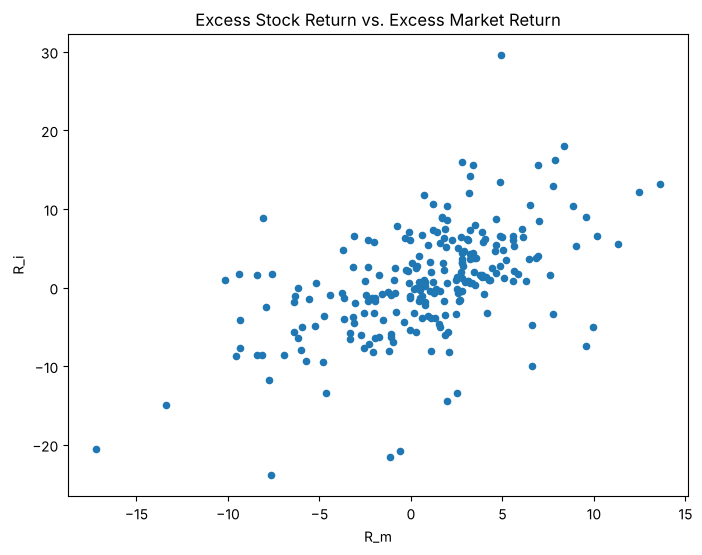

In [31]:
returns.plot.scatter(x='R_m', y='R_i', title='Excess Stock Return vs. Excess Market Return', figsize=(8, 6))

## Estimate CAPM

<mark>Q: How to estimate the CAPM alpha and beta by regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set the dependent variable `y` to `returns['R_i']` and the independent variable `X` to `returns['R_m']`, add a constant to `X` with `sm.add_constant()` for the intercept, then create an OLS model and fit it into `capm_results`. Uncomment and run the following code.

In [32]:
# Define the dependent variable (y) and independent variable (X)
y = returns['R_i']
X = returns['R_m']

# Add a constant to the independent variable for the intercept term (alpha)
X = sm.add_constant(X)

# Create and fit the OLS model
model = sm.OLS(y, X)
capm_results = model.fit()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Print the regression results with `capm_results.summary()`.

In [33]:
print(capm_results.summary())

                            OLS Regression Results                            
Dep. Variable:                    R_i   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.280
Method:                 Least Squares   F-statistic:                     92.39
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           1.20e-18
Time:                        12:43:28   Log-Likelihood:                -749.46
No. Observations:                 236   AIC:                             1503.
Df Residuals:                     234   BIC:                             1510.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0558      0.385      0.145      0.8

## Regression Line

<mark>Q: How to add the fitted regression line on top of a scatter plot?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Re-draw the scatter plot keeping its axes as `ax`, then add the fitted CAPM line in red using `capm_results.predict(sm.add_constant(returns['R_m']))`; set the title and axis labels, and turn on the grid and legend. Uncomment and run the following code.

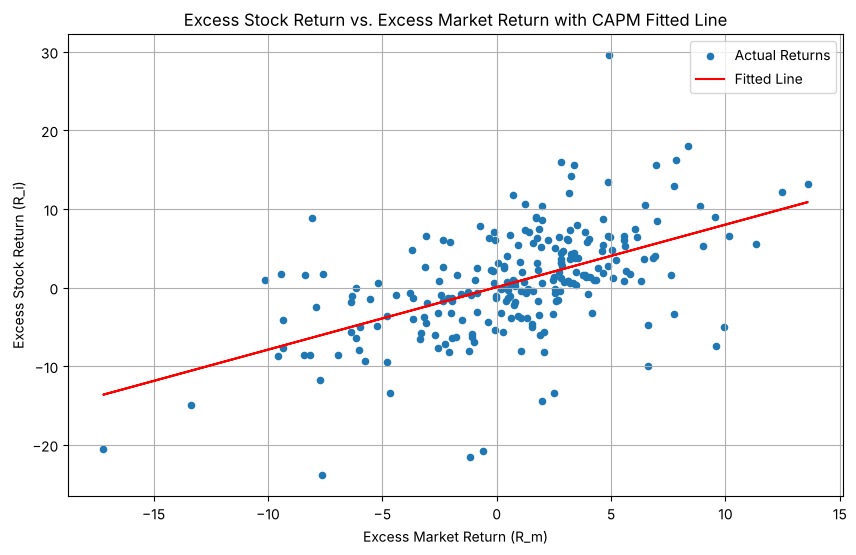

In [34]:
# Create the scatter plot using pandas plotting functionality and get the axes object
ax = returns.plot.scatter(x='R_m', y='R_i', figsize=(10, 6), label='Actual Returns')

# Plot the regression line on the same axes
# The independent variable X already includes the constant for prediction
ax.plot(returns['R_m'],
        capm_results.predict(sm.add_constant(returns['R_m'])),
        color='red', label='Fitted Line')

ax.set_title('Excess Stock Return vs. Excess Market Return with CAPM Fitted Line')
ax.set_xlabel('Excess Market Return (R_m)')
ax.set_ylabel('Excess Stock Return (R_i)')
ax.grid(True)
ax.legend()

## Intercept and Slope

* The regression model:

$$R_t = \alpha + \beta \times R_{M,t}  + \epsilon_t$$
(Recall $R_t$  and $R_{M,t}$ are excess returns, at time $t$)

* We can extract the intercept and slope estimate in the following way:

<mark>Q: How to extract the intercept and the slope from a fitted regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the intercept estimate from `capm_results.params['const']` into `alpha`, and display it.

In [35]:
alpha = capm_results.params['const']
alpha

np.float64(0.05582871865251948)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the slope estimate from `capm_results.params['R_m']` into `beta`, and display it.

In [36]:
beta = capm_results.params['R_m']
beta

np.float64(0.7953248610715165)

## Idiosyncratic Risk and Systematic Risk

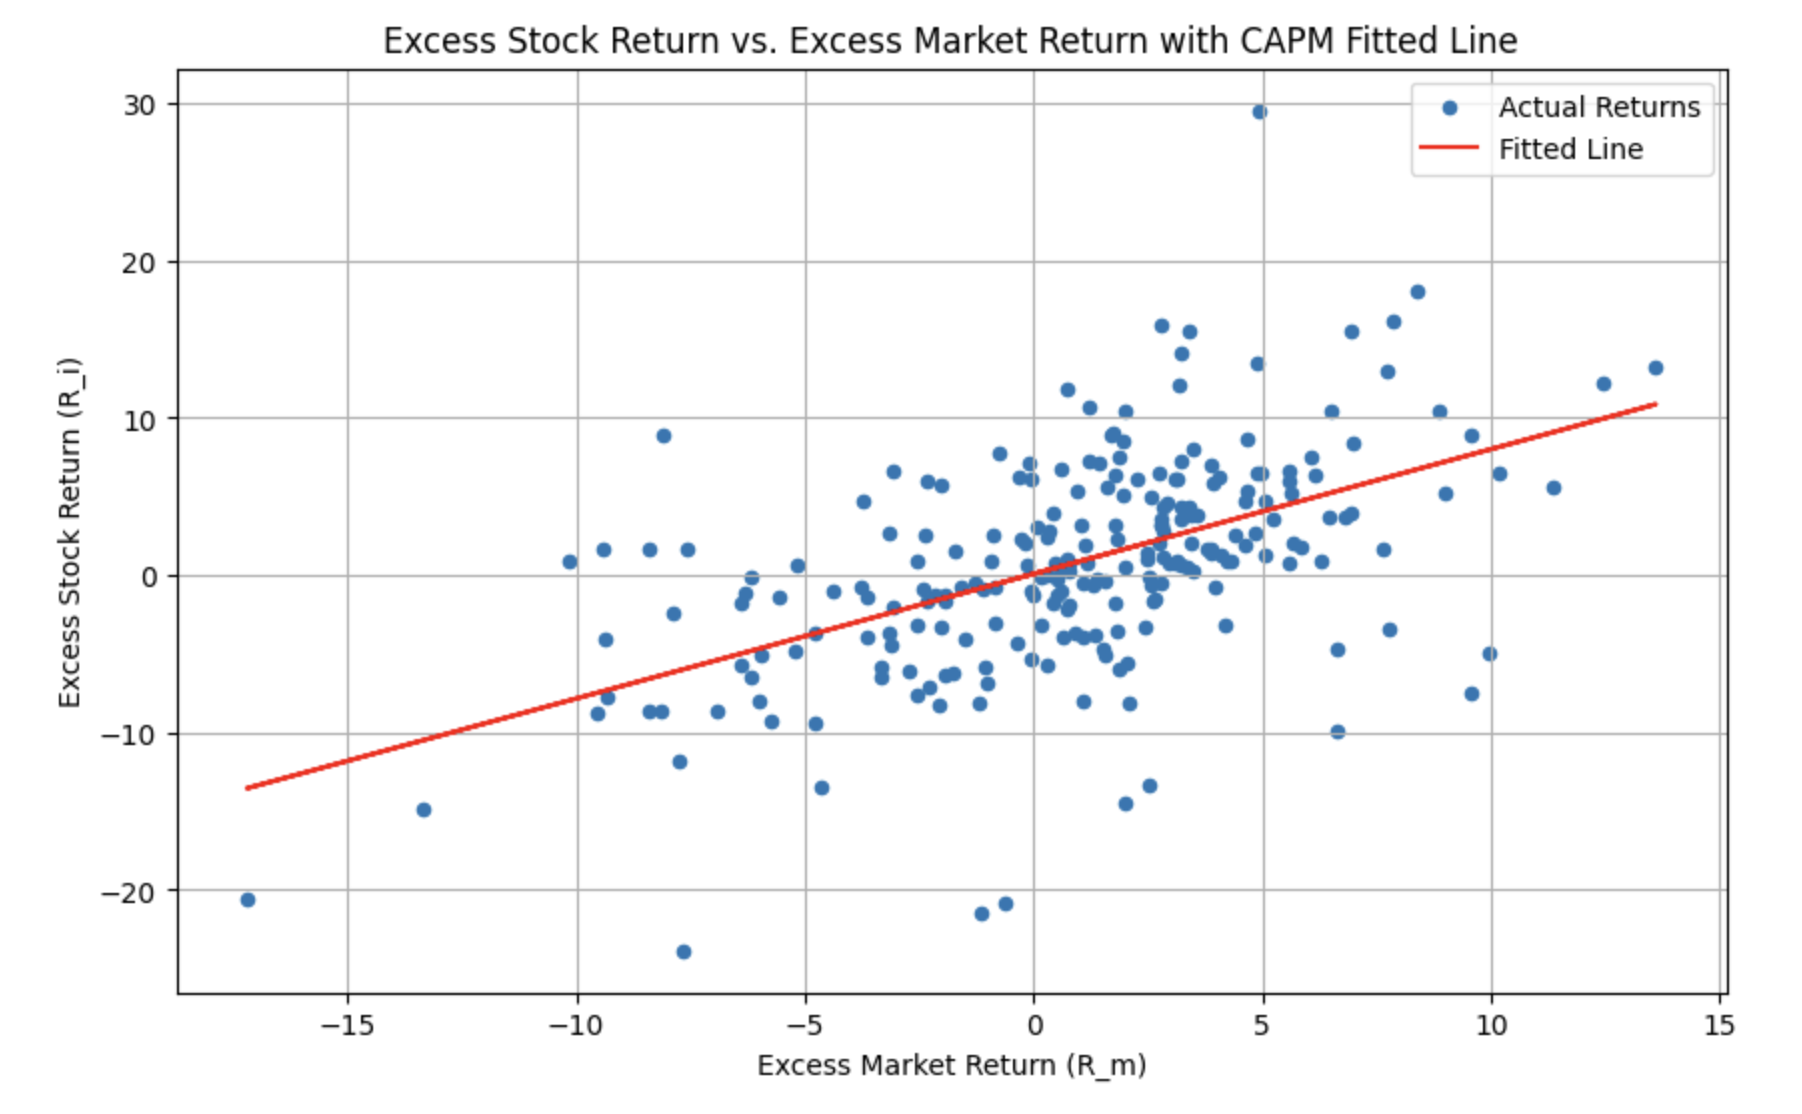

## Idiosyncratic Risk

<mark>Q: What is idiosyncratic risk, and how to measure it from the regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Get the regression residuals from `capm_results.resid` and store them in `CAPM_resid`.

In [37]:
CAPM_resid = capm_results.resid

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `CAPM_resid` with the title `"Residuals"`.

<Axes: title={'center': 'Residuals'}, xlabel='Date'>

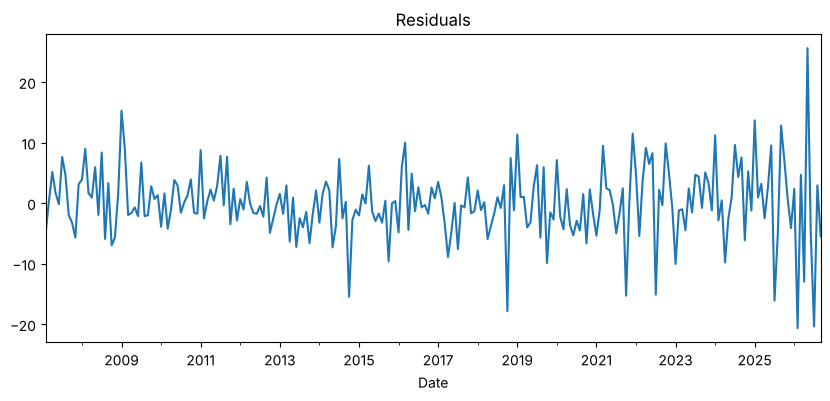

In [38]:
CAPM_resid.plot(title='Residuals', figsize=(10, 4))

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the idiosyncratic risk as the variance of the residuals with `.var()`, store it in `idiosyncratic_risk`, and display it.

In [39]:
idiosyncratic_risk = CAPM_resid.var()
idiosyncratic_risk

np.float64(33.70861466584528)

## Risk Decomposition

### Risk Decomposition: The Calculation

<mark>Q: How to decompose total risk into systematic risk and idiosyncratic risk?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the total risk as the variance of `returns['R_i']`, store it in `total_risk`, and display it.

In [40]:
total_risk = returns['R_i'].var()
total_risk

np.float64(47.01766297884844)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the systematic risk as `total_risk` minus `idiosyncratic_risk`, store it in `systematic_risk`, and display it.

In [41]:
systematic_risk = total_risk - idiosyncratic_risk
systematic_risk

np.float64(13.30904831300316)

### Risk Decomposition: The Theory

* Again, from the regression model:

$$R_t = \alpha + \beta \times R_{M,t}  + \epsilon_t$$


* Taking variance of both sides:

$$\begin{aligned}
var(R_{t})	&= var(\alpha+\beta\times R_{M,t}+\epsilon_{t}) \\
	&= var(\beta\times R_{M,t}+\epsilon_{t}) \\
	&= var(\beta\times R_{M,t})+var(\epsilon_{t}) \\
	&= \beta^{2}\times var(R_{M,t})+var(\epsilon_{t})
 \end{aligned}$$



* Therefore systematic risk can also be calculated as $\beta^{2}\times var(R_{M,t})$

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the theory by computing `beta**2` times the variance of `returns['R_m']`, and compare it with the systematic risk you just calculated.

In [42]:
print(beta**2 * returns['R_m'].var(), systematic_risk)

13.309048313003172 13.30904831300316


## Time-varying Beta

* Beta estimates depend on the time window chosen.
* Let's find out how the beta changes by rolling the window over time.

### Regression Function

* First we define a function that returns the regression beta (we will apply this function to a rolling window):

<mark>Q: How to estimate a beta that changes over time?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Define a function `get_beta(y_window)` that takes a rolling window of `R_i` values, picks the matching `R_m` values over the same dates, adds a constant, fits an OLS model, and returns the coefficient on `R_m`. Uncomment and run the following code.

In [43]:
def get_beta(y_window):
    # y_window is the rolling window of R_i values
    idx = y_window.index                      # the dates in this window
    X = returns.loc[idx, 'R_m']               # matching R_m over the same dates
    X = sm.add_constant(X)
    model = sm.OLS(y_window, X)
    results = model.fit()
    return results.params['R_m']                  # 1 = coefficient for R_m column

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Test `get_beta()` on the whole sample and print its result next to `beta`, to check the two agree.

In [44]:
print(get_beta(returns['R_i']), beta)

0.7953248610715165 0.7953248610715165


### Rolling Window Regression

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Apply `get_beta` to a rolling 60-month window of `returns['R_i']` with `.rolling(window=60).apply()`, and store the result in `rolling_betas`.

In [45]:
rolling_betas = returns['R_i'].rolling(window=60).apply(get_beta)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `rolling_betas` with the title `"Time-Varying Beta, window size = 60 months"`.

<Axes: title={'center': 'Time-Varying Beta, window size = 60 months'}, xlabel='Date'>

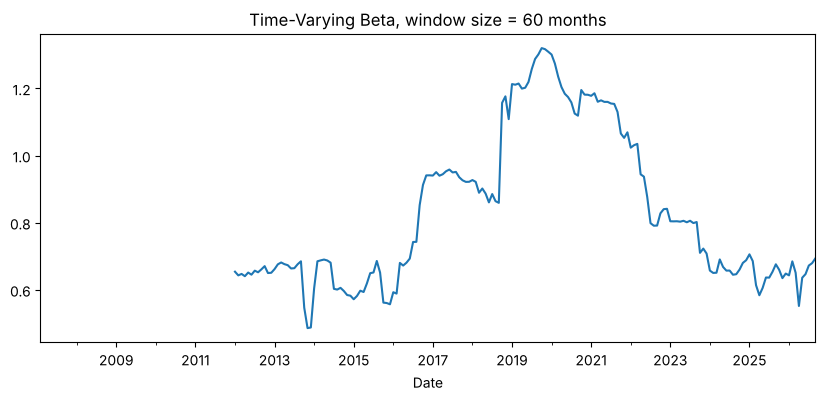

In [46]:
rolling_betas.plot(title='Time-Varying Beta, window size = 60 months', figsize=(10, 4))

# Size and Book-to-Market

## Portfolios Formed on Size and Book-to-Market

* Fama and French study portfolios formed based on firm size and book-to-market ratio. 
  - Sort all stocks according to size (market equity, ME) into 5 groups 
  - Within each size group, sort the stocks based on the ratio of book equity to market equity (BE/ME).
  - This generates an intersection of 25 portfolios.

### 25 Portfolios Formed on Size and Book-to-Market

* The returns on the 25 portfolios formed on size and book-to-market can be downloaded from Ken French's data library at http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Download the 25 portfolios formed on size and book-to-market into `ff25`. Uncomment and run the following code.

In [47]:
# Fama-French 3 factors (monthly)
ff25 = pdr.DataReader("25_Portfolios_5x5", "famafrench",start="1900-1-1")

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Take table `[0]` from `ff25` into `size_BM_portfolios`, and display its first few rows.

In [48]:
size_BM_portfolios = ff25[0]
size_BM_portfolios.head()

,SMALL LoBM,ME1 BM2,ME1 BM3,ME1 BM4,SMALL HiBM,ME2 BM1,ME2 BM2,ME2 BM3,ME2 BM4,ME2 BM5,...,ME4 BM1,ME4 BM2,ME4 BM3,ME4 BM4,ME4 BM5,BIG LoBM,ME5 BM2,ME5 BM3,ME5 BM4,BIG HiBM
Date,,,,,,,,,,,,,,,,,,,,,
1926-07,3.7806,-0.4119,-1.9223,-0.4114,1.9583,1.2118,2.4107,0.6056,-2.6082,-0.4527,...,1.5376,1.5460,1.4956,0.2765,2.4678,3.4622,6.0909,1.9613,3.1263,0.5623
1926-08,-2.2074,-8.7275,2.4557,1.3500,8.5104,2.3620,-0.7525,3.8984,0.2299,6.2937,...,1.3858,3.8587,1.8133,2.1336,5.3422,1.0169,4.1975,2.0113,5.4924,7.7576
1926-09,-6.2460,-0.3260,-6.1982,-1.6318,0.8586,-2.6849,-0.5252,1.0789,-3.2877,-0.9419,...,1.6897,-0.5246,-1.5012,1.4806,0.8730,-1.2951,3.6610,0.0640,-0.7497,-2.4284
1926-10,-8.6155,-3.7532,-5.6787,5.7170,-2.5452,-2.8014,-4.4191,-5.0767,-8.0271,-1.3213,...,-3.9136,-2.6528,-1.9143,-3.2532,-5.3525,-2.7382,-3.0061,-2.2679,-4.6725,-5.8129
1926-11,3.4744,6.6476,2.2414,-4.7021,0.5110,3.1023,-1.7317,3.0425,4.9538,2.7292,...,3.4492,2.3823,3.9124,5.1102,1.8213,4.4331,2.5355,1.5190,3.6596,2.5636


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the average return of each column with `.mean()`, store it in `average_returns`, and display it.

In [49]:
average_returns = size_BM_portfolios.mean()
average_returns

SMALL LoBM    0.838151
ME1 BM2       0.954012
ME1 BM3       1.253097
ME1 BM4       1.411957
SMALL HiBM    1.614884
ME2 BM1       0.933413
ME2 BM2       1.212947
ME2 BM3       1.246073
ME2 BM4       1.307455
ME2 BM5       1.502835
ME3 BM1       0.996335
ME3 BM2       1.177281
ME3 BM3       1.176819
ME3 BM4       1.266228
ME3 BM5       1.374943
ME4 BM1       0.993324
ME4 BM2       1.046589
ME4 BM3       1.122419
ME4 BM4       1.234099
ME4 BM5       1.300307
BIG LoBM      0.962643
ME5 BM2       0.928660
ME5 BM3       0.994234
ME5 BM4       0.941194
BIG HiBM      1.275920
dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Reshape `average_returns` into a 5x5 matrix with `.values.reshape(5, 5)`, and build a DataFrame `average_returns_mat` whose index is the size groups `['SMALL', 'ME2', 'ME3', 'ME4', 'BIG']` and whose columns are the book-to-market groups `['LoBM', 'BM2', 'BM3', 'BM4', 'HiBM']`. Uncomment and run the following code.

In [50]:
# Reshape into a 5x5 Matrix
# The raw data is ordered: (Small-LoBM, Small-2... Small-Hi), then (ME2-LoBM...), etc.
# Reshaping creates a DataFrame where Index=Size, Columns=BM
matrix_data = average_returns.values.reshape(5, 5)

average_returns_mat = pd.DataFrame(
    matrix_data,
    index=['SMALL', 'ME2', 'ME3', 'ME4', 'BIG'],  # Size groups
    columns=['LoBM', 'BM2', 'BM3', 'BM4', 'HiBM'] # Book-to-Market groups. The sub-groups
)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display `average_returns_mat`.

In [51]:
average_returns_mat

,LoBM,BM2,BM3,BM4,HiBM
SMALL,0.838151,0.954012,1.253097,1.411957,1.614884
ME2,0.933413,1.212947,1.246073,1.307455,1.502835
ME3,0.996335,1.177281,1.176819,1.266228,1.374943
ME4,0.993324,1.046589,1.122419,1.234099,1.300307
BIG,0.962643,0.928660,0.994234,0.941194,1.275920


<mark>Q: How to show average returns across size and book-to-market groups in one picture?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw a heat map of `average_returns_mat` with `sns.heatmap()`. Uncomment and run the following code.

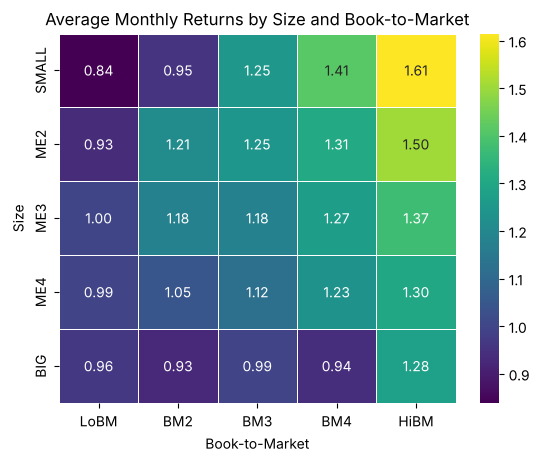

In [52]:
sns.heatmap(average_returns_mat, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Average Monthly Returns by Size and Book-to-Market')
plt.xlabel('Book-to-Market')
plt.ylabel('Size')
plt.show()

## Empirical Difficulty of CAPM

* The popularity of the CAPM is due to its simplicity and it is grounded in finance theory. 
* However, the CAPM has not performed well in empirical testing. 
  - It cannot explain the difference in average return between small stocks and big stocks. 
  - It cannot explain the difference in average return between value stocks (stocks with high book-to-market ratio) and growth stocks (stocks with low book-to-market ratio). 
* This suggests other factors may need to be added to help explain the remaining variation in asset returns unexplained by the market. 
  - One such model that has gained popularity, especially in the academic community, is the Fama-French Three Factor (FF) Model.

# Fama-French Three-Factor Model

<mark>Q: What are the three factors in the Fama-French model?</mark>

* In the FF Model, we have

$$r-r_{f}=\beta\times\left(r_{M}-r_{f}\right)+h\times HML+s\times SMB$$

where
  - HML is the difference in the returns of portfolios with high B/M ratios and low B/M ratios
  - SMB is the difference in returns of portfolios of small company stocks and big company stocks.

## Factor Data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ We have already downloaded the Fama-French Research Data Factor from Ken French's data library at http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html.

Check the first few rows of `ff_monthly`.

In [53]:
ff_monthly.head()

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07,2.89,-2.42,-2.75,0.22
1926-08,2.64,-1.44,4.13,0.25
1926-09,0.38,-1.36,0.05,0.23
1926-10,-3.27,-0.18,0.78,0.32
1926-11,2.54,-0.17,-0.48,0.31


## Mutual Fund

* Mutual funds are investments that pool your money together with other investors to purchase shares of a collection of stocks, bonds, or other securities, referred to as a portfolio, that might be difficult to recreate on your own. Mutual funds are typically overseen by a portfolio manager.

* As an example, we will study the performance of the fund called LSV Value Equity (LSVEX).

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set `fund_symbol` to `"LSVEX"` and download its data into `fund_data` with `yf.download()` from `start="1900-01-01"`, using `auto_adjust=True`, `multi_level_index=False` and `progress=False`. Uncomment and run the following code:

In [54]:
fund_symbol = "LSVEX"
fund_data = yf.download(fund_symbol,
                  start="1900-01-01",
                  auto_adjust=True,
                  multi_level_index=False,
                  progress=False)


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `fund_data`.

In [55]:
fund_data.head()

,Close,High,Low,Open,Volume
Date,,,,,
1999-03-31,2.956042,2.956042,2.956042,2.956042,0
1999-04-01,2.964911,2.964911,2.964911,2.964911,0
1999-04-05,3.000382,3.000382,3.000382,3.000382,0
1999-04-06,2.985602,2.985602,2.985602,2.985602,0
1999-04-07,3.000382,3.000382,3.000382,3.000382,0


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot the `"Close"` column of `fund_data` with the title `"LSVEX"`.

<Axes: title={'center': 'LSVEX'}, xlabel='Date'>

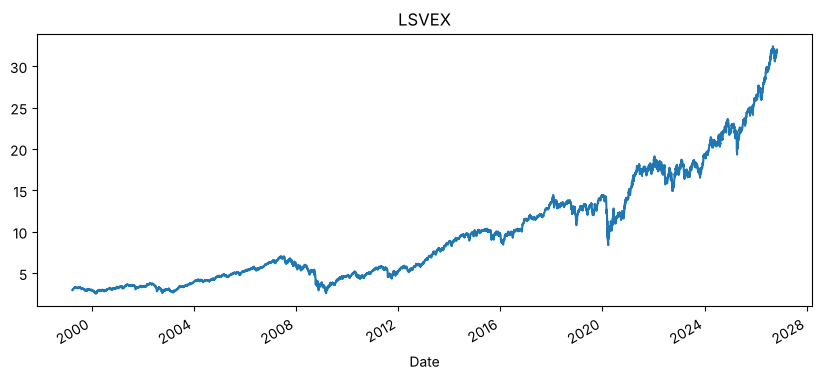

In [56]:
fund_data['Close'].plot(title='LSVEX', figsize=(10, 4))

## Mutual fund returns

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `getMonthlyReturn()` to calculate the fund's monthly return, naming it `"r_p"`, and store it in `r_p`.

In [57]:
r_p = getMonthlyReturn(fund_data, 'r_p')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_p`.

In [58]:
r_p.head()

Date
1999-04    8.600006
1999-05    0.184176
1999-06    1.378639
1999-07   -2.447851
1999-08   -3.810393
Freq: M, Name: r_p, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_p` with the title `"Monthly Return of LSVEX"`.

<Axes: title={'center': 'Monthly Return of LSVEX'}, xlabel='Date'>

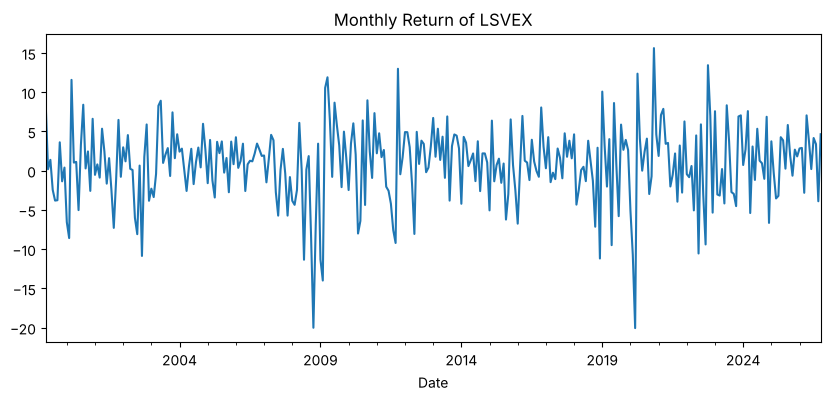

In [59]:
r_p.plot(title='Monthly Return of LSVEX', figsize=(10, 4))

## Merging the data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Concatenate `ff_monthly` and `r_p` along the columns with `pd.concat(..., axis=1)`, and store the result in `ff_returns`.

In [60]:
ff_returns = pd.concat([ff_monthly, r_p], axis=1)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the last few rows of `ff_returns` with `.tail()`.

In [61]:
ff_returns.tail()

,Mkt-RF,SMB,HML,RF,r_p
Date,,,,,
2026-06,-1.07,3.39,3.58,0.29,0.203457
2026-07,-0.61,-1.92,2.11,0.33,4.162442
2026-08,2.56,0.34,-3.54,0.29,3.378814
2026-09,-1.07,-3.16,-1.55,0.31,-3.896919
2026-10,NaN,NaN,NaN,NaN,4.643558


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Drop the rows with missing values from `ff_returns` using `dropna(inplace=True)`.

In [62]:
ff_returns.dropna(inplace=True)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `ff_returns`.

In [63]:
ff_returns.head()

,Mkt-RF,SMB,HML,RF,r_p
Date,,,,,
1999-04,4.34,3.88,2.38,0.37,8.600006
1999-05,-2.46,3.34,2.50,0.34,0.184176
1999-06,4.77,3.21,-3.22,0.40,1.378639
1999-07,-3.49,2.49,-0.18,0.38,-2.447851
1999-08,-1.37,-0.94,-1.92,0.39,-3.810393


## Excess Returns

Since we will run regression on excess returns (i.e. in excess of the risk-free rate), let’s calculate the excess returns on the mutual fund and save it as column `R_p`:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the fund's excess return as `r_p` minus `RF`, and store it in a new column `"R_p"`.

In [64]:
ff_returns['R_p'] = ff_returns['r_p'] - ff_returns['RF']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `ff_returns`.

In [65]:
ff_returns.head()

,Mkt-RF,SMB,HML,RF,r_p,R_p
Date,,,,,,
1999-04,4.34,3.88,2.38,0.37,8.600006,8.230006
1999-05,-2.46,3.34,2.50,0.34,0.184176,-0.155824
1999-06,4.77,3.21,-3.22,0.40,1.378639,0.978639
1999-07,-3.49,2.49,-0.18,0.38,-2.447851,-2.827851
1999-08,-1.37,-0.94,-1.92,0.39,-3.810393,-4.200393


## Fama-French 3-Factor Model Regression

<mark>Q: How to estimate the Fama-French three-factor model by regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set `y` to `ff_returns['R_p']` and `X` to the three factors `ff_returns[['Mkt-RF', 'SMB', 'HML']]`, add a constant, fit an OLS model into `FF_results`, and print its summary. Uncomment and run the following code.

In [66]:
# Define the dependent variable (y)
y = ff_returns['R_p']

# Define the independent variables (X)
# Ensure column names match 'Mkt-RF' as it is in FF_factors
X = ff_returns[['Mkt-RF', 'SMB', 'HML']]

# Add a constant to the independent variable for the intercept term
X = sm.add_constant(X)

# Create and fit the OLS model
FF_model = sm.OLS(y, X)
FF_results = FF_model.fit()

# Display the regression results
print(FF_results.summary())

                            OLS Regression Results                            
Dep. Variable:                    R_p   R-squared:                       0.928
Model:                            OLS   Adj. R-squared:                  0.928
Method:                 Least Squares   F-statistic:                     1408.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          3.56e-186
Time:                        12:43:32   Log-Likelihood:                -555.41
No. Observations:                 330   AIC:                             1119.
Df Residuals:                     326   BIC:                             1134.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0510      0.073     -0.699      0.4

## Compared to CAPM

<mark>Q: How to tell whether the three-factor model explains the fund's returns better than the CAPM?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Run the same regression again with only `'Mkt-RF'` as the independent variable, fit it into `CAPM_results`, and print the summary so the two models can be compared. Uncomment and run the following code.

In [67]:
# Define the dependent variable (y) for CAPM
y = ff_returns['R_p']

# Define the independent variable (X) for CAPM (only Mkt-RF)
X = ff_returns['Mkt-RF']

# Add a constant to the independent variable for the intercept term
X = sm.add_constant(X)

# Create and fit the OLS model for CAPM
CAPM_model = sm.OLS(y, X)
CAPM_results = CAPM_model.fit()

# Display the regression results
print(CAPM_results.summary())

                            OLS Regression Results                            
Dep. Variable:                    R_p   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     990.0
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          4.37e-101
Time:                        12:43:32   Log-Likelihood:                -760.83
No. Observations:                 330   AIC:                             1526.
Df Residuals:                     328   BIC:                             1533.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0516      0.135      0.381      0.7